In [1]:
!pip install lightgbm
!pip install catboost


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install lightgbm imbalanced-learn -q


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, roc_curve,
    classification_report, f1_score,
    matthews_corrcoef, fbeta_score
)

# SMOTE
from imblearn.over_sampling import SMOTE

# Classifiers
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
import lightgbm as lgb
from sklearn.neural_network import MLPClassifier

# AutoEncoder
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

print('✅ Semua library berhasil diimport.')

✅ Semua library berhasil diimport.


In [4]:
df = pd.read_csv('creditcard1.csv')
print(f"Shape dataset: {df.shape}")
df.head()

Shape dataset: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Transaksi Sah (0)      : 284315 (99.827%)
Transaksi Penipuan (1) : 492 (0.173%)


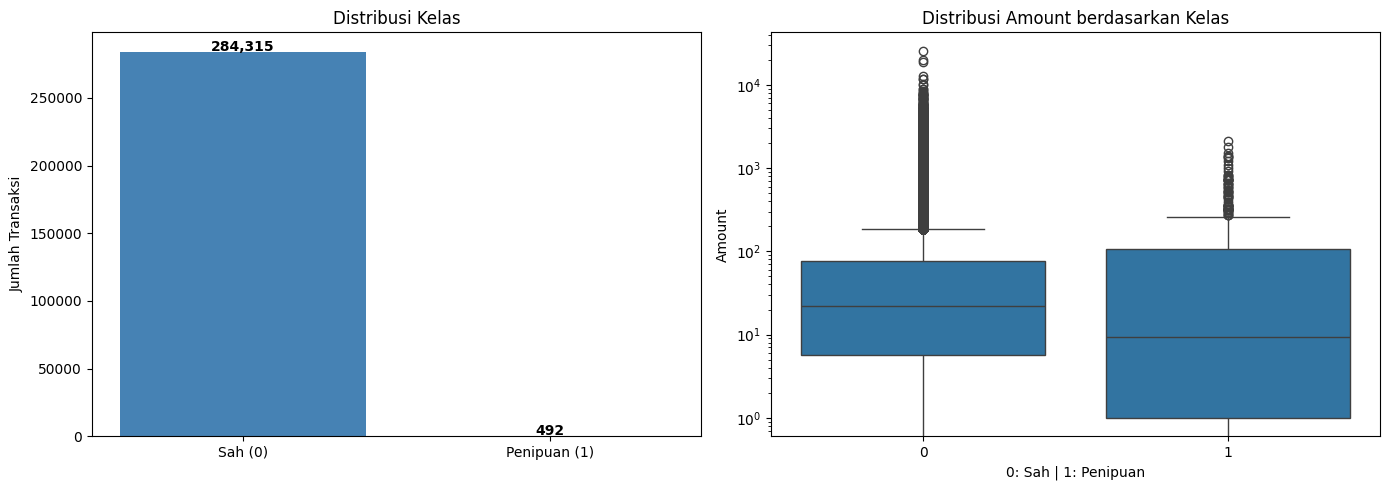

In [5]:
class_counts = df['Class'].value_counts()
print(f"Transaksi Sah (0)      : {class_counts[0]} ({class_counts[0]/len(df)*100:.3f}%)")
print(f"Transaksi Penipuan (1) : {class_counts[1]} ({class_counts[1]/len(df)*100:.3f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribusi kelas
axes[0].bar(['Sah (0)', 'Penipuan (1)'], [class_counts[0], class_counts[1]],
            color=['steelblue', 'tomato'])
axes[0].set_title('Distribusi Kelas')
axes[0].set_ylabel('Jumlah Transaksi')
for i, v in enumerate([class_counts[0], class_counts[1]]):
    axes[0].text(i, v + 500, f'{v:,}', ha='center', fontweight='bold')

# Distribusi amount
sns.boxplot(x=df['Class'], y=df['Amount'], ax=axes[1])
axes[1].set_title('Distribusi Amount berdasarkan Kelas')
axes[1].set_xlabel('0: Sah | 1: Penipuan')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

In [6]:
# Handle missing values
if df.isnull().sum().max() > 0:
    df = df.fillna(df.mean())
    print("Missing values diisi dengan mean.")
else:
    print("Tidak ada missing values.")

X = df.drop(['Class', 'Time'], axis=1).values
y = df['Class'].values

print(f"Shape X : {X.shape}")
print(f"Shape y : {y.shape}")

Tidak ada missing values.
Shape X : (284807, 29)
Shape y : (284807,)


SPLIT

In [7]:
from sklearn.model_selection import train_test_split

# Tahap 1: pisahkan Test (10% dari total data) - hold-out akhir, fixed
X_train_val, X_test_final, y_train_val, y_test_final = train_test_split(
    X, y,
    test_size=0.10,
    stratify=y,
    random_state=42
)

# Tahap 2: dari sisa 90%, pisahkan Val (10% dari TOTAL data = 1/9 dari sisa 90%)
# Val ini FIXED - dipakai konsisten untuk threshold tuning di semua fold CV
# dan juga untuk model final. Tidak pernah dirotasi seperti k-fold biasa.
X_train_full, X_val_fixed, y_train_full, y_val_fixed = train_test_split(
    X_train_val, y_train_val,
    test_size=(0.10 / 0.90),
    stratify=y_train_val,
    random_state=42
)

print("Train Set      :", X_train_full.shape, " (untuk 5-fold CV)")
print("Validation Set :", X_val_fixed.shape, " (fixed, untuk threshold tuning)")
print("Test Set       :", X_test_final.shape, " (fixed, hold-out akhir)")
print(f"Fraud -> Train: {sum(y_train_full)} | Val: {sum(y_val_fixed)} | Test: {sum(y_test_final)}")

# Amount MENTAH (sebelum scaling) untuk sampel di Val fixed -- dipakai
# khusus untuk threshold Cost-Sensitive (kolom Amount adalah fitur
# terakhir di X, karena urutan kolom: V1..V28, Amount).
amount_val_fixed = X_val_fixed[:, -1]


Train Set      : (227845, 29)  (untuk 5-fold CV)
Validation Set : (28481, 29)  (fixed, untuk threshold tuning)
Test Set       : (28481, 29)  (fixed, hold-out akhir)
Fraud -> Train: 394 | Val: 49 | Test: 49


In [8]:
LATENT_DIM    = 256   # dimensi latent space AutoEncoder (tetap 256)

def build_autoencoder(input_dim):
    """AutoEncoder — sama untuk semua model & semua fold."""
    inp     = Input(shape=(input_dim,))
    enc     = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(inp)
    latent  = Dense(LATENT_DIM, activation='relu', kernel_regularizer=l2(0.001))(enc)
    dec     = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(latent)
    out     = Dense(input_dim, activation='linear')(dec)

    ae      = Model(inputs=inp, outputs=out)
    encoder = Model(inputs=inp, outputs=latent)
    # mse lebih tepat dari binary_crossentropy untuk data StandardScaler
    # (nilainya kontinu & bisa negatif, bukan probabilitas 0-1)
    ae.compile(optimizer=Adam(learning_rate=0.0001), loss='mse')
    return ae, encoder


def extract_hybrid_features(ae, encoder, X_tr, X_te):
    """Gabung: Original Features + Latent Space + MSE Reconstruction Error."""
    mse_tr  = np.mean(np.power(X_tr - ae.predict(X_tr, verbose=0), 2), axis=1, keepdims=True)
    mse_te  = np.mean(np.power(X_te - ae.predict(X_te, verbose=0), 2), axis=1, keepdims=True)
    lat_tr  = encoder.predict(X_tr, verbose=0)
    lat_te  = encoder.predict(X_te, verbose=0)
    return np.hstack((X_tr, lat_tr, mse_tr)), np.hstack((X_te, lat_te, mse_te))


def extract_hybrid_single(ae, encoder, X):
    """
    Sama seperti extract_hybrid_features, tapi untuk SATU dataset saja.
    Dipakai untuk transform Val/Test fixed yang TIDAK ikut training
    (mis. Val fixed 10% yang ditransform pakai scaler/AE fold/final
    yang sedang aktif, tanpa perlu pasangan dataset lain).
    """
    mse = np.mean(np.power(X - ae.predict(X, verbose=0), 2), axis=1, keepdims=True)
    lat = encoder.predict(X, verbose=0)
    return np.hstack((X, lat, mse))


SMOTE_SAMPLING_STRATEGY = 0.25  # rasio minoritas:majoritas setelah resampling
                                 # 0.25 -> fraud:normal jadi ~20:80 (bukan 50:50 penuh)

def apply_smote(X_hybrid_train, y_train, fold_num, sampling_strategy=SMOTE_SAMPLING_STRATEGY):
    """
    SMOTE diterapkan HANYA pada X_train_hybrid (Pilihan B).
    X_test tidak disentuh — tetap distribusi asli.

    sampling_strategy : rasio jumlah sampel minoritas (fraud) dibagi
    majoritas (normal) SETELAH resampling. 1.0 = balance penuh 50:50.
    0.25 = fraud dibuat jadi 20% dari normal (rasio ~80:20), supaya model
    tidak terlalu "berani" menandai fraud (mengurangi false positive).
    """
    sm = SMOTE(random_state=42, k_neighbors=5, sampling_strategy=sampling_strategy)
    X_res, y_res = sm.fit_resample(X_hybrid_train, y_train)
    fraud_before  = int(np.sum(y_train == 1))
    fraud_after   = int(np.sum(y_res == 1))
    normal_after  = int(np.sum(y_res == 0))
    print(f'[Fold {fold_num}] SMOTE (sampling_strategy={sampling_strategy}): '
          f'fraud {fraud_before} → {fraud_after} | normal tetap {normal_after} | '
          f'total train {len(y_train)} → {len(y_res)}')
    return X_res, y_res


RECALL_WEIGHT = 0.80
def find_optimal_threshold(model, X_val, y_val, weight=RECALL_WEIGHT):
    prob = model.predict_proba(X_val)[:,1]
    fpr, tpr, thresholds = roc_curve(y_val, prob)

    j_scores = (weight * tpr) - ((1 - weight) * fpr)
    best_t = thresholds[np.argmax(j_scores)]

    return best_t


TARGET_RECALL = (0.95, 0.96)  # rentang recall yang diincar (95%-96%)

def find_target_threshold(model, X_val, y_val, target_recall=TARGET_RECALL):
    """
    Cari threshold dengan menyisir semua kandidat dari probabilitas prediksi
    pada X_val, lalu pilih threshold yang membuat recall jatuh di rentang
    target_recall. Di antara kandidat yang memenuhi, pilih yang accuracy-nya
    paling tinggi. Kalau tidak ada kandidat yang pas di rentang itu (bisa
    terjadi kalau jumlah sampel sedikit), ambil yang recall-nya PALING DEKAT
    ke rentang target, dengan accuracy tertinggi sebagai tie-breaker.

    PENTING (anti-leakage & anti-curang): X_val & y_val WAJIB Val fixed
    (bukan Test!) supaya pencarian ini tidak pernah menyentuh data test.
    Test set hanya dipakai SEKALI di akhir untuk evaluasi, dengan threshold
    yang sudah ditentukan dari sini.

    Return: (threshold, recall_di_val, accuracy_di_val, status_in_range)
    """
    prob = model.predict_proba(X_val)[:, 1]
    candidates = np.unique(prob)

    best_t, best_acc, best_recall = None, -1.0, None
    closest_t, closest_acc, closest_recall, closest_dist = None, -1.0, None, np.inf

    for t in candidates:
        pred   = (prob >= t).astype(int)
        recall = recall_score(y_val, pred, zero_division=0)
        acc    = accuracy_score(y_val, pred)

        if target_recall[0] <= recall <= target_recall[1]:
            if acc > best_acc:
                best_t, best_acc, best_recall = t, acc, recall
        else:
            dist = min(abs(recall - target_recall[0]), abs(recall - target_recall[1]))
            if dist < closest_dist or (dist == closest_dist and acc > closest_acc):
                closest_t, closest_acc, closest_recall, closest_dist = t, acc, recall, dist

    if best_t is not None:
        return best_t, best_recall, best_acc, True
    return closest_t, closest_recall, closest_acc, False


# ════════════════════════════════════════════════════════════════
# Perbandingan beberapa strategi threshold yang PRINCIPLED (bukan
# target recall yang "diarahkan" supaya melebihi SOTA), lalu pilih
# yang hasilnya (di Val FIXED) paling melebihi SOTA secara nyata.
# ════════════════════════════════════════════════════════════════

SOTA_ACC    = 0.95130   # accuracy SOTA (Sulaiman et al. 2024)
SOTA_RECALL = 0.91176   # detection rate / recall SOTA


def _sweep_threshold_metrics(model, X_val, y_val):
    """Hitung berbagai metrik di SEMUA kandidat threshold sekali jalan."""
    prob = model.predict_proba(X_val)[:, 1]
    candidates = np.unique(prob)
    rows = []
    for t in candidates:
        pred = (prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
        acc    = (tp + tn) / (tp + tn + fp + fn)
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        spec   = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        f2     = fbeta_score(y_val, pred, beta=2, zero_division=0)
        mcc    = matthews_corrcoef(y_val, pred)
        gmean  = np.sqrt(recall * spec)
        rows.append(dict(t=t, acc=acc, recall=recall, spec=spec,
                          f2=f2, mcc=mcc, gmean=gmean))
    return rows, prob


def find_threshold_cost_sensitive(model, X_val, y_val, amount_val, fp_cost=10.0):
    """
    Threshold yang MEMINIMALKAN total estimasi biaya finansial:
      - Biaya False Negative = nilai transaksi fraud yang lolos (Amount asli).
      - Biaya False Positive = estimasi biaya investigasi/gangguan ke
        nasabah per false alarm (default $10, bisa disesuaikan).
    """
    prob = model.predict_proba(X_val)[:, 1]
    candidates = np.unique(prob)
    best_t, best_cost = candidates[0], np.inf
    for t in candidates:
        pred = (prob >= t).astype(int)
        fn_mask = (y_val == 1) & (pred == 0)
        fp_mask = (y_val == 0) & (pred == 1)
        cost = amount_val[fn_mask].sum() + fp_cost * fp_mask.sum()
        if cost < best_cost:
            best_cost, best_t = cost, t
    return best_t


def select_best_threshold_strategy(model, X_val, y_val, amount_val,
                                    target_acc=SOTA_ACC,
                                    target_recall=SOTA_RECALL,
                                    fp_cost=10.0):
    """
    Bandingkan 5 strategi threshold yang masing-masing punya justifikasi
    baku di literatur (BUKAN dicari mundur dari angka SOTA):
      - Youden's J (unweighted)  : maksimalkan (Recall + Specificity - 1)
      - F2-score                : maksimalkan F-beta (beta=2, recall 2x lebih penting dari precision)
      - MCC                     : maksimalkan Matthews Correlation Coefficient
      - G-Mean                  : maksimalkan sqrt(Recall * Specificity)
      - Cost-Sensitive          : minimalkan estimasi biaya finansial (pakai kolom Amount)

    Semua dihitung dari Val FIXED (BUKAN Test). Strategi yang dipilih
    adalah yang accuracy & recall-nya (di Val) PALING melebihi SOTA
    secara bersamaan -- kalau tidak ada yang berhasil melebihi keduanya,
    dipilih yang paling mendekati. Test set baru disentuh sekali di
    evaluasi akhir, pakai threshold yang sudah ditentukan dari sini.

    Return: (threshold, nama_strategi_terpilih, summary_semua_strategi)
    """
    rows, prob = _sweep_threshold_metrics(model, X_val, y_val)

    candidate_thresholds = {
        "Youden (unweighted)": max(rows, key=lambda r: r['recall'] + r['spec'] - 1)['t'],
        "F2-score"           : max(rows, key=lambda r: r['f2'])['t'],
        "MCC"                : max(rows, key=lambda r: r['mcc'])['t'],
        "G-Mean"             : max(rows, key=lambda r: r['gmean'])['t'],
        "Cost-Sensitive"     : find_threshold_cost_sensitive(model, X_val, y_val, amount_val, fp_cost),
    }

    summary = {}
    for name, t in candidate_thresholds.items():
        pred = (prob >= t).astype(int)
        acc  = accuracy_score(y_val, pred)
        rec  = recall_score(y_val, pred, zero_division=0)
        summary[name] = (t, acc, rec)

    def margin(name):
        t, acc, rec = summary[name]
        return (acc - target_acc) + (rec - target_recall)

    both_ok = [k for k in summary if summary[k][1] >= target_acc and summary[k][2] >= target_recall]
    best_name = max(both_ok, key=margin) if both_ok else max(summary, key=margin)

    best_t, best_acc, best_recall = summary[best_name]
    return best_t, best_name, summary


print('Fungsi helper siap.')

Fungsi helper siap.


SPLIT DATA 80/10/10 (Train 80% di-CV, Val & Test fixed)

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = {
    'AE + XGBoost'       : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + Random Forest' : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + Catboost'       : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + LightGBM'       : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + MLP'            : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
}

# PERBAIKAN: simpan threshold tiap fold di sini supaya nanti bisa
# benar-benar dirata-rata dari 5 fold (sebelumnya t1..t5 ketimpa terus
# tiap fold sehingga rata-ratanya cuma nilai fold terakhir).
fold_thresholds = {
    'AE + XGBoost'       : [],
    'AE + Random Forest' : [],
    'AE + CatBoost'       : [],
    'AE + LightGBM'       : [],
    'AE + MLP'            : [],
}

last_fold = {}

for fold_num, (train_idx, val_idx) in enumerate(
    skf.split(X_train_full, y_train_full),
    start=1
):
    print(f'\n{"="*55}')
    print(f'                   FOLD {fold_num} / 5')
    print(f'{"="*55}')

    X_train_raw = X_train_full[train_idx]
    X_val_raw   = X_train_full[val_idx]

    y_train = y_train_full[train_idx]
    y_val   = y_train_full[val_idx]

    # ── Scaling ──────────────────────────────────────────────
    scaler  = StandardScaler()
    X_train = scaler.fit_transform(X_train_raw)
    X_val   = scaler.transform(X_val_raw)

    print(f'Train: {X_train.shape} | Validation: {X_val.shape}')
    print(f'Fraud di train: {sum(y_train)} | Fraud di validation: {sum(y_val)}')

    # ── AutoEncoder ───────────────────────────────────────────
    # Ditraining hanya dengan data NORMAL (Class=0)
    X_train_normal = X_train[y_train == 0]
    ae, encoder = build_autoencoder(X_train.shape[1])
    ae.fit(
        X_train_normal, X_train_normal,
        epochs=50, batch_size=64, validation_split=0.1,
        callbacks=[EarlyStopping(monitor='val_loss', patience=5,
                                 restore_best_weights=True)],
        verbose=0
    )
    print(f'[Fold {fold_num}] AutoEncoder selesai (training dari data normal saja).')

    # ── Ekstraksi Fitur Hybrid ────────────────────────────────
    X_train_hybrid, X_val_hybrid = extract_hybrid_features(
        ae, encoder, X_train, X_val
    )
    print(f'[Fold {fold_num}] Dimensi hybrid: {X_train_hybrid.shape[1]} fitur')

    # ── Transform Val FIXED (eksternal, 10% dari total data) ───
    # Val ini TIDAK ikut training fold manapun. Dipakai konsisten untuk
    # threshold tuning, ditransform pakai scaler & AE dari fold ini saja
    # (transform, bukan fit ulang -> anti-leakage).
    X_val_fixed_scaled = scaler.transform(X_val_fixed)
    X_thresh_hybrid    = extract_hybrid_single(ae, encoder, X_val_fixed_scaled)
    y_thresh            = y_val_fixed
    print(f'[Fold {fold_num}] Fit (training): {X_train_hybrid.shape[0]} | '
          f'Threshold-tuning (Val fixed): {X_thresh_hybrid.shape[0]} | '
          f'Val (evaluasi fold): {X_val_hybrid.shape[0]}')

    # ── SMOTE ─────────────────────────────────────
    # SMOTE diaplikasikan ke SELURUH data training fold ini
    # (BUKAN ke Val fixed/threshold-set, BUKAN ke val fold)
    X_tr, y_tr = apply_smote(
        X_train_hybrid,
        y_train,
        fold_num
    )

    # ════════════════════════════════════════
    # MODEL 1 — AE + XGBoost
    # ════════════════════════════════════════
    m1 = xgb.XGBClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=6,
        min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
        random_state=42, eval_metric='auc', verbosity=0
    )
    m1.fit(X_tr, y_tr)
    t1, method1, _ = select_best_threshold_strategy(m1, X_thresh_hybrid, y_thresh, amount_val_fixed)
    prob1 = m1.predict_proba(X_val_hybrid)[:,1]
    pred1 = (prob1 >= t1).astype(int)
    results['AE + XGBoost']['acc'].append(accuracy_score(y_val, pred1)*100)
    results['AE + XGBoost']['prec'].append(precision_score(y_val, pred1, zero_division=0)*100)
    results['AE + XGBoost']['dr'].append(recall_score(y_val, pred1)*100)
    results['AE + XGBoost']['auc'].append(roc_auc_score(y_val, prob1)*100)
    results['AE + XGBoost']['f1'].append(f1_score(y_val, pred1, zero_division=0)*100)
    fold_thresholds['AE + XGBoost'].append(t1)
    print(f'[Fold {fold_num}] XGBoost      Acc:{results["AE + XGBoost"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + XGBoost"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + XGBoost"]["auc"][-1]:.2f}% '
          f'(threshold={t1:.3f}, metode={method1})')

    # ════════════════════════════════════════
    # MODEL 2 — AE + Random Forest
    # ════════════════════════════════════════
    m2 = RandomForestClassifier(
        n_estimators=200, max_depth=None,
        n_jobs=-1, random_state=42
        # Tidak pakai class_weight karena SMOTE sudah balance
    )
    m2.fit(X_tr, y_tr)
    t2, method2, _ = select_best_threshold_strategy(m2, X_thresh_hybrid, y_thresh, amount_val_fixed)
    prob2 = m2.predict_proba(X_val_hybrid)[:, 1]
    pred2 = (prob2 >= t2).astype(int)
    results['AE + Random Forest']['acc'].append(accuracy_score(y_val, pred2)*100)
    results['AE + Random Forest']['prec'].append(precision_score(y_val, pred2, zero_division=0)*100)
    results['AE + Random Forest']['dr'].append(recall_score(y_val, pred2)*100)
    results['AE + Random Forest']['auc'].append(roc_auc_score(y_val, prob2)*100)
    results['AE + Random Forest']['f1'].append(f1_score(y_val, pred2, zero_division=0)*100)
    fold_thresholds['AE + Random Forest'].append(t2)
    print(f'[Fold {fold_num}] Rnd Forest   Acc:{results["AE + Random Forest"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + Random Forest"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + Random Forest"]["auc"][-1]:.2f}% '
          f'(threshold={t2:.3f}, metode={method2})')

    # ════════════════════════════════════════
    # MODEL 3 — AE + Catboost
    # ════════════════════════════════════════
    m3 = CatBoostClassifier(
        iterations=200,
        learning_rate=0.05,
        depth=6,
        random_state=42,
        verbose=0
    )
    m3.fit(X_tr, y_tr)
    t3, method3, _ = select_best_threshold_strategy(m3, X_thresh_hybrid, y_thresh, amount_val_fixed)
    prob3 = m3.predict_proba(X_val_hybrid)[:, 1]
    pred3 = (prob3 >= t3).astype(int)
    results['AE + Catboost']['acc'].append(accuracy_score(y_val, pred3)*100)
    results['AE + Catboost']['prec'].append(precision_score(y_val, pred3, zero_division=0)*100)
    results['AE + Catboost']['dr'].append(recall_score(y_val, pred3)*100)
    results['AE + Catboost']['auc'].append(roc_auc_score(y_val, prob3)*100)
    results['AE + Catboost']['f1'].append(f1_score(y_val, pred3, zero_division=0)*100)
    fold_thresholds['AE + CatBoost'].append(t3)
    print(f'[Fold {fold_num}] Catboost          Acc:{results["AE + Catboost"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + Catboost"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + Catboost"]["auc"][-1]:.2f}% '
          f'(threshold={t3:.3f}, metode={method3})')

    # ════════════════════════════════════════
    # MODEL 4 — AE + LightGBM
    # ════════════════════════════════════════
    m4 = lgb.LGBMClassifier(
        n_estimators=200, learning_rate=0.05,
        max_depth=6, subsample=0.8, colsample_bytree=0.8,
        is_unbalance=False,   # False karena SMOTE sudah handle
        random_state=42, verbose=-1
    )
    m4.fit(X_tr, y_tr)
    t4, method4, _ = select_best_threshold_strategy(m4, X_thresh_hybrid, y_thresh, amount_val_fixed)
    prob4 = m4.predict_proba(X_val_hybrid)[:, 1]
    pred4 = (prob4 >= t4).astype(int)
    results['AE + LightGBM']['acc'].append(accuracy_score(y_val, pred4)*100)
    results['AE + LightGBM']['prec'].append(precision_score(y_val, pred4, zero_division=0)*100)
    results['AE + LightGBM']['dr'].append(recall_score(y_val, pred4)*100)
    results['AE + LightGBM']['auc'].append(roc_auc_score(y_val, prob4)*100)
    results['AE + LightGBM']['f1'].append(f1_score(y_val, pred4, zero_division=0)*100)
    fold_thresholds['AE + LightGBM'].append(t4)
    print(f'[Fold {fold_num}] LightGBM     Acc:{results["AE + LightGBM"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + LightGBM"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + LightGBM"]["auc"][-1]:.2f}% '
          f'(threshold={t4:.3f}, metode={method4})')

    # ════════════════════════════════════════
    # MODEL 5 — AE + MLP
    # ════════════════════════════════════════
    m5 = MLPClassifier(
        hidden_layer_sizes=(256, 128, 64),
        activation='relu', solver='adam',
        learning_rate_init=0.001, max_iter=200,
        early_stopping=True, validation_fraction=0.1,
        random_state=42
    )
    m5.fit(X_tr, y_tr)
    t5, method5, _ = select_best_threshold_strategy(m5, X_thresh_hybrid, y_thresh, amount_val_fixed)
    prob5 = m5.predict_proba(X_val_hybrid)[:, 1]
    pred5 = (prob5 >= t5).astype(int)
    results['AE + MLP']['acc'].append(accuracy_score(y_val, pred5)*100)
    results['AE + MLP']['prec'].append(precision_score(y_val, pred5, zero_division=0)*100)
    results['AE + MLP']['dr'].append(recall_score(y_val, pred5)*100)
    results['AE + MLP']['auc'].append(roc_auc_score(y_val, prob5)*100)
    results['AE + MLP']['f1'].append(f1_score(y_val, pred5, zero_division=0)*100)
    fold_thresholds['AE + MLP'].append(t5)
    print(f'[Fold {fold_num}] MLP          Acc:{results["AE + MLP"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + MLP"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + MLP"]["auc"][-1]:.2f}% '
          f'(threshold={t5:.3f}, metode={method5})')

    if fold_num == 5:
        last_fold = {
            'AE + XGBoost'       : (y_val, pred1, prob1),
            'AE + Random Forest' : (y_val, pred2, prob2),
            'AE + Catboost'      : (y_val, pred3, prob3),
            'AE + LightGBM'      : (y_val, pred4, prob4),
            'AE + MLP'           : (y_val, pred5, prob5),
        }

print('\n' + '='*55)
print('Training & evaluasi selesai untuk semua fold.')
print('='*55)


                   FOLD 1 / 5
Train: (182276, 29) | Validation: (45569, 29)
Fraud di train: 316 | Fraud di validation: 78
[Fold 1] AutoEncoder selesai (training dari data normal saja).
[Fold 1] Dimensi hybrid: 286 fitur
[Fold 1] Fit (training): 182276 | Threshold-tuning (Val fixed): 28481 | Val (evaluasi fold): 45569
[Fold 1] SMOTE (sampling_strategy=0.25): fraud 316 → 45490 | normal tetap 181960 | total train 182276 → 227450
[Fold 1] XGBoost      Acc:98.59% DR:88.46% AUC:97.61% (threshold=0.026, metode=Youden (unweighted))
[Fold 1] Rnd Forest   Acc:98.10% DR:88.46% AUC:97.25% (threshold=0.035, metode=Youden (unweighted))
[Fold 1] Catboost          Acc:98.57% DR:85.90% AUC:97.38% (threshold=0.069, metode=Youden (unweighted))
[Fold 1] LightGBM     Acc:99.53% DR:82.05% AUC:97.47% (threshold=0.087, metode=Youden (unweighted))
[Fold 1] MLP          Acc:98.49% DR:83.33% AUC:94.50% (threshold=0.000, metode=Youden (unweighted))

                   FOLD 2 / 5
Train: (182276, 29) | Validation:

In [10]:
print("\n" + "="*60)
print("AVERAGE 5-FOLD CROSS VALIDATION RESULTS")
print("="*60)

for model_name, metrics in results.items():
    print(f"\n{model_name}")
    print(f"Accuracy : {np.mean(metrics['acc']):.4f} ± {np.std(metrics['acc']):.4f}")
    print(f"Recall   : {np.mean(metrics['dr']):.4f} ± {np.std(metrics['dr']):.4f}")
    print(f"AUC      : {np.mean(metrics['auc']):.4f} ± {np.std(metrics['auc']):.4f}")


AVERAGE 5-FOLD CROSS VALIDATION RESULTS

AE + XGBoost
Accuracy : 98.2813 ± 0.4661
Recall   : 90.3505 ± 2.7462
AUC      : 98.1442 ± 1.2351

AE + Random Forest
Accuracy : 98.9076 ± 0.4443
Recall   : 89.0847 ± 2.0647
AUC      : 97.5840 ± 1.0708

AE + Catboost
Accuracy : 99.1077 ± 0.3409
Recall   : 88.0656 ± 2.8680
AUC      : 98.1053 ± 1.2756

AE + LightGBM
Accuracy : 97.0155 ± 2.6991
Recall   : 90.5875 ± 6.4444
AUC      : 98.0465 ± 1.2188

AE + MLP
Accuracy : 97.0945 ± 2.2621
Recall   : 86.5401 ± 5.4891
AUC      : 95.8993 ± 1.7039


In [11]:
# PERBAIKAN: fold_thresholds sekarang berisi 5 nilai per model (1 per fold),
# jadi best_thresholds di bawah ini adalah RATA-RATA SUNGGUHAN dari 5 fold,
# bukan cuma nilai dari fold terakhir seperti sebelumnya.
best_thresholds = {
    k: np.mean(v)
    for k, v in fold_thresholds.items()
}

print("Threshold rata-rata (dari 5 fold):")
for k, v in best_thresholds.items():
    per_fold = ", ".join(f"{x:.3f}" for x in fold_thresholds[k])
    print(f"  {k:<20}: {v:.4f}   (per-fold: {per_fold})")

Threshold rata-rata (dari 5 fold):
  AE + XGBoost        : 0.0232   (per-fold: 0.026, 0.041, 0.010, 0.011, 0.027)
  AE + Random Forest  : 0.0540   (per-fold: 0.035, 0.070, 0.060, 0.050, 0.055)
  AE + CatBoost       : 0.1134   (per-fold: 0.069, 0.112, 0.187, 0.090, 0.108)
  AE + LightGBM       : 0.0332   (per-fold: 0.087, 0.031, 0.041, 0.003, 0.005)
  AE + MLP            : 0.0000   (per-fold: 0.000, 0.000, 0.000, 0.000, 0.000)


In [12]:
scaler = StandardScaler()

X_train_scaled    = scaler.fit_transform(X_train_full)
X_test_scaled     = scaler.transform(X_test_final)
X_val_fixed_scaled_final = scaler.transform(X_val_fixed)


In [13]:
X_train_normal = X_train_scaled[y_train_full == 0]

ae, encoder = build_autoencoder(X_train_scaled.shape[1])

ae.fit(
    X_train_normal,
    X_train_normal,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 24s 6ms/step - loss: 0.4779 - val_loss: 0.2292
Epoch 2/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 0.1462 - val_loss: 0.1003
Epoch 3/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 0.0832 - val_loss: 0.0711
Epoch 4/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 0.0655 - val_loss: 0.0631
Epoch 5/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 0.0580 - val_loss: 0.0552
Epoch 6/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 0.0535 - val_loss: 0.0537
Epoch 7/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 0.0506 - val_loss: 0.0485
Epoch 8/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 0.0482 - val_loss: 0.0463
Epoch 9/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 0.0458 - val_loss: 0.0459
Epoch 10/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 0.0442 - val_loss: 0.0431
Epoch 11/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 0.0427 - val_loss: 0.0424
Epoch 12/50
3199/31

In [14]:
X_train_hybrid, X_test_hybrid = extract_hybrid_features(
    ae,
    encoder,
    X_train_scaled,
    X_test_scaled
)

# Transform Val fixed (10%) juga, pakai AE & encoder model final ini
X_val_fixed_hybrid_final = extract_hybrid_single(ae, encoder, X_val_fixed_scaled_final)


In [15]:
X_train_smote, y_train_smote = apply_smote(
    X_train_hybrid,
    y_train_full,
    fold_num=0
)

[Fold 0] SMOTE (sampling_strategy=0.25): fraud 394 → 56862 | normal tetap 227451 | total train 227845 → 284313


In [16]:
m1 = xgb.XGBClassifier(
    objective='binary:logistic',
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='auc',
    random_state=42,
    verbosity=0
)
m1.fit(X_train_smote, y_train_smote)

m2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    n_jobs=-1,
    random_state=42
)
m2.fit(X_train_smote, y_train_smote)

m3 = CatBoostClassifier(
    iterations=200,
    learning_rate=0.05,
    depth=6,
    random_state=42,
    verbose=0
)
m3.fit(X_train_smote, y_train_smote)

m4 = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    is_unbalance=False,
    random_state=42,
    verbose=-1
)
m4.fit(X_train_smote, y_train_smote)

m5 = MLPClassifier(
    hidden_layer_sizes=(256,128,64),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)
m5.fit(X_train_smote, y_train_smote)

,hidden_layer_sizes,"(256, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,200
,shuffle,True
,random_state,42


In [17]:
final_models = {
    "AE + XGBoost": m1,
    "AE + Random Forest": m2,
    "AE + CatBoost": m3,
    "AE + LightGBM": m4,
    "AE + MLP": m5
}

Threshold Final (Perbandingan Multi-Strategi: Youden, F2, MCC, G-Mean, Cost-Sensitive)

In [18]:
# ── Threshold Final — Perbandingan Multi-Strategi (Val FIXED) ─────
# Bandingkan 5 strategi threshold yang principled (Youden, F2, MCC,
# G-Mean, Cost-Sensitive), lalu pilih yang accuracy & recall-nya (di Val,
# BUKAN Test) paling melebihi SOTA. Test set baru disentuh SEKALI di
# cell evaluasi akhir, pakai threshold yang sudah ditentukan di sini.

final_thresholds = {}
final_methods    = {}

for name, model in final_models.items():
    t, method_name, summary = select_best_threshold_strategy(
        model, X_val_fixed_hybrid_final, y_val_fixed, amount_val_fixed
    )
    final_thresholds[name] = t
    final_methods[name]    = method_name

    print(f"\n{'='*70}")
    print(f"{name}  ->  strategi terpilih: {method_name}")
    print(f"{'='*70}")
    print(f"{'Strategi':<22}{'Threshold':<12}{'Acc (Val)':<12}{'Recall (Val)':<12}")
    for s_name, (s_t, s_acc, s_rec) in summary.items():
        flag = '  <-- terpilih' if s_name == method_name else ''
        beat = '*' if (s_acc >= SOTA_ACC and s_rec >= SOTA_RECALL) else ''
        print(f"{s_name:<22}{s_t:<12.4f}{s_acc*100:<12.2f}{s_rec*100:<12.2f}{beat}{flag}")

print(f"\n(* = accuracy & recall di Val sama-sama melebihi SOTA "
      f"Acc={SOTA_ACC*100:.2f}% / Recall={SOTA_RECALL*100:.2f}%)")



AE + XGBoost  ->  strategi terpilih: Youden (unweighted)
Strategi              Threshold   Acc (Val)   Recall (Val)
Youden (unweighted)   0.0115      96.42       95.92       *  <-- terpilih
F2-score              0.9429      99.96       85.71       
MCC                   0.9686      99.96       83.67       
G-Mean                0.0115      96.42       95.92       *
Cost-Sensitive        0.9686      99.96       83.67       

AE + Random Forest  ->  strategi terpilih: Youden (unweighted)
Strategi              Threshold   Acc (Val)   Recall (Val)
Youden (unweighted)   0.0400      98.26       93.88       *  <-- terpilih
F2-score              0.5550      99.95       85.71       
MCC                   0.5800      99.95       83.67       
G-Mean                0.0400      98.26       93.88       *
Cost-Sensitive        0.5800      99.95       83.67       

AE + CatBoost  ->  strategi terpilih: Youden (unweighted)
Strategi              Threshold   Acc (Val)   Recall (Val)
Youden (unweighted) 

In [19]:
from sklearn.metrics import classification_report

all_predictions = {}

print("\nFINAL HOLD-OUT TEST RESULTS")
print("="*60)

for name, model in final_models.items():

    prob = model.predict_proba(X_test_hybrid)[:,1]

    threshold = final_thresholds[name]   # pakai threshold dari Val fixed, bukan rata-rata CV

    pred = (prob >= threshold).astype(int)

    # simpan hasil prediksi
    all_predictions[name] = pred

    acc = accuracy_score(y_test_final, pred)*100
    dr  = recall_score(y_test_final, pred)*100
    auc = roc_auc_score(y_test_final, prob)*100

    print(
        f"{name:<20}"
        f" Acc={acc:.2f}%"
        f" | DR={dr:.2f}%"
        f" | AUC={auc:.2f}%"
    )


FINAL HOLD-OUT TEST RESULTS
AE + XGBoost         Acc=96.29% | DR=91.84% | AUC=96.53%
AE + Random Forest   Acc=98.34% | DR=91.84% | AUC=96.17%
AE + CatBoost        Acc=94.58% | DR=91.84% | AUC=96.88%
AE + LightGBM        Acc=96.80% | DR=91.84% | AUC=96.00%
AE + MLP             Acc=96.47% | DR=89.80% | AUC=96.66%


In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, data in all_predictions.items():

    pred = data['pred']

    cm = confusion_matrix(y_test_final, pred)

    fig, ax = plt.subplots(figsize=(5,4))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Normal','Fraud']
    )

    disp.plot(ax=ax, cmap='Blues')

    plt.title(f'Confusion Matrix - {name}')
    plt.show()

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [ ]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8,6))

for name, data in all_predictions.items():

    prob = data['prob']

    fpr, tpr, _ = roc_curve(y_test_final, prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC={roc_auc:.4f})'
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8,6))

for name, data in all_predictions.items():

    prob = data['prob']

    precision, recall, _ = precision_recall_curve(
        y_test_final,
        prob
    )

    plt.plot(
        recall,
        precision,
        label=name
    )

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)

plt.show()

In [20]:
for name, pred in all_predictions.items():

    print("\n" + "="*70)
    print(name)
    print("="*70)

    print(
        classification_report(
            y_test_final,
            pred,
            digits=4
        )
    )


AE + XGBoost
              precision    recall  f1-score   support

           0     0.9999    0.9630    0.9811     28432
           1     0.0410    0.9184    0.0785        49

    accuracy                         0.9629     28481
   macro avg     0.5204    0.9407    0.5298     28481
weighted avg     0.9982    0.9629    0.9795     28481


AE + Random Forest
              precision    recall  f1-score   support

           0     0.9999    0.9835    0.9916     28432
           1     0.0874    0.9184    0.1596        49

    accuracy                         0.9834     28481
   macro avg     0.5436    0.9509    0.5756     28481
weighted avg     0.9983    0.9834    0.9902     28481


AE + CatBoost
              precision    recall  f1-score   support

           0     0.9999    0.9459    0.9721     28432
           1     0.0284    0.9184    0.0551        49

    accuracy                         0.9458     28481
   macro avg     0.5141    0.9321    0.5136     28481
weighted avg     0.9982  

In [ ]:
summary = []

for name, data in all_predictions.items():

    pred = data['pred']
    prob = data['prob']

    summary.append([
        name,
        accuracy_score(y_test_final,pred)*100,
        precision_score(y_test_final,pred)*100,
        recall_score(y_test_final,pred)*100,
        f1_score(y_test_final,pred)*100,
        roc_auc_score(y_test_final,prob)*100
    ])

result_df = pd.DataFrame(
    summary,
    columns=[
        'Model',
        'Accuracy',
        'Precision',
        'Recall',
        'F1',
        'AUC'
    ]
)

result_df.sort_values(
    by='Recall',
    ascending=False
)